In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## hyperparameter-surface

**Validation loss over a sweep of learning rate and weight decay.** Contours interpolate a 13 × 13 grid of runs on log-spaced axes, and the red circle marks the run with the lowest loss. Validation loss is lowest, 1.91, at learning rate 3.2e-4 and weight decay 5.6e-3, and climbs to 3.8–4.5 at the largest learning rate, 0.01, where training diverges.

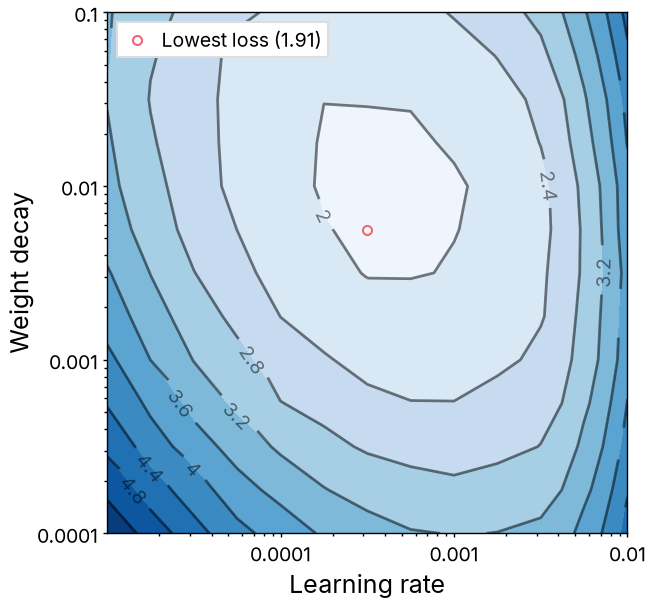

In [2]:
with open("../hyperparameter-surface.json") as f:
    data = json.load(f)
learning_rate = np.array(data["learning_rate"])
weight_decay = np.array(data["weight_decay"])
val_loss = np.array(data["val_loss"])
best_i, best_j = np.unravel_index(val_loss.argmin(), val_loss.shape)

fig, ax = plt.subplots(figsize=(3.25, 3))
cs = ax.contourf(learning_rate, weight_decay, val_loss, levels=10)
lines = ax.contour(learning_rate, weight_decay, val_loss, levels=cs.levels, colors="black", alpha=0.5)
ax.plot(learning_rate[best_j], weight_decay[best_i], "o", color=colors["ours"],
        label=f"Lowest loss ({val_loss.min():.3g})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1e-4, 1e-3, 1e-2], labels=["0.0001", "0.001", "0.01"])
ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1], labels=["0.0001", "0.001", "0.01", "0.1"])
ax.grid(False)
ax.set_xlabel("Learning rate")
ax.set_ylabel("Weight decay")
ax.legend(loc="upper left")

fit_height(fig, ax, aspect=1.0)
# clabel puts some labels on short line pieces at the panel edge, where they get cut off; drop those
for text in ax.clabel(lines, fmt="%.2g"):
    if not ax.bbox.contains(*text.get_window_extent().p0) or not ax.bbox.contains(*text.get_window_extent().p1):
        text.remove()
fig.savefig("hyperparameter-surface.pdf")
fig.savefig("hyperparameter-surface.png")
plt.show()